# Experiment 1: Average Salary by Department

**Name:** Rudra Gupta  
**SAP ID:** 500120437

**Aim:**
1. Install the packages required for analytics in Python.
2. Load a CSV file (Kaggle dataset) containing employee information and draw a graph showing the average salary department-wise.

**Dataset:** [Human Resources Data Set - Kaggle](https://www.kaggle.com/datasets/rhuebner/human-resources-data-set) (`HRDataset_v14.csv`, kept in this folder).

## Step 1: Install the required packages

In [1]:
%pip install pandas numpy matplotlib --quiet

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Step 2: Import the libraries

In [2]:
import numpy as np
import pandas as pd

print("pandas:", pd.__version__)
print("numpy :", np.__version__)

pandas: 2.3.3
numpy : 1.26.4


### Chart style

In [3]:
import matplotlib.pyplot as plt

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e8e7e3"
BLUE, BLUE_LIGHT, MUTED = "#2a78d6", "#9ec5f4", "#8a8984"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 11, "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 15, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 28,
    "figure.dpi": 110,
})


def titles(ax, title, subtitle=None):
    ax.set_title(title, color=INK)
    if subtitle:
        ax.annotate(subtitle, xy=(0, 1), xycoords="axes fraction", xytext=(0, 7),
                    textcoords="offset points", color=INK2, fontsize=10.5, va="bottom")


def hbar(ax, labels, values, color=BLUE, fmt="{:,.0f}", highlight=None, highlight_color=BLUE):
    """Horizontal bars, largest at the top, with the value printed at the end of each bar."""
    labels, values = list(labels)[::-1], list(values)[::-1]
    colors = [highlight_color if l == highlight else color for l in labels]
    bars = ax.barh(labels, values, color=colors, height=0.68, edgecolor=SURFACE, linewidth=2)
    vmax = max(values)
    for b, v in zip(bars, values):
        ax.text(b.get_width() + vmax * 0.012, b.get_y() + b.get_height() / 2, fmt.format(v),
                va="center", fontsize=10, color=INK, zorder=4,
                bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5))
    ax.set_xlim(0, vmax * 1.14)
    ax.xaxis.set_visible(False)
    ax.spines[["bottom", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0, labelsize=10.5, labelcolor=INK)

## Step 3: Load the CSV file

In [4]:
df = pd.read_csv("HRDataset_v14.csv")
print("Shape of dataset:", df.shape)
df[["Employee_Name", "Department", "Position", "Salary"]].head()

Shape of dataset: (311, 36)


,Employee_Name,Department,Position,Salary
0,"Adinolfi, Wilson K",Production,Production Technician I,62506
1,"Ait Sidi, Karthikeyan",IT/IS,Sr. DBA,104437
2,"Akinkuolie, Sarah",Production,Production Technician II,64955
3,"Alagbe,Trina",Production,Production Technician I,64991
4,"Anderson, Carol",Production,Production Technician I,50825


## Step 4: Clean the department names
Department names in the file have trailing spaces (e.g. `'Production       '`), which would split one department into two groups.

In [5]:
df["Department"] = df["Department"].str.strip()
df["Department"].value_counts()

Department
Production              209
IT/IS                    50
Sales                    31
Software Engineering     11
Admin Offices             9
Executive Office          1
Name: count, dtype: int64

## Step 5: Average salary for each department

In [6]:
avg_salary = df.groupby("Department")["Salary"].mean().round(2).sort_values(ascending=False)
avg_salary.to_frame("Average Salary ($)")

,Average Salary ($)
Department,
Executive Office,250000.00
IT/IS,97064.64
Software Engineering,94989.45
Admin Offices,71791.89
Sales,69061.26
Production,59953.55


## Step 6: Graph - average salary department-wise

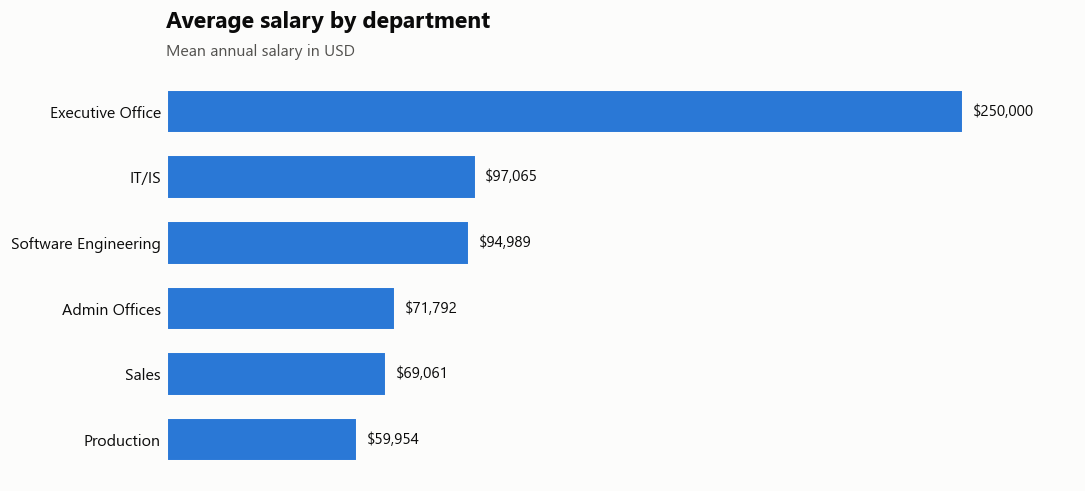

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.6))
hbar(ax, avg_salary.index, avg_salary.values, fmt="${:,.0f}")
titles(ax, "Average salary by department", "Mean annual salary in USD")
plt.tight_layout()
plt.show()

## Conclusion
We installed pandas, numpy and matplotlib, loaded the Kaggle employee CSV with pandas, grouped employees by department and plotted the average salary. The Executive Office has the highest average (it has one employee, the CEO), followed by IT/IS and Software Engineering; Production has the lowest.